# LLM Post-Training with Verifiable Rewards

Qwen2.5-3B adaptation for structured letter counting using LoRA and GRPO. This notebook retains the recorded experiment outputs. Use a compatible CUDA environment; observed package versions are documented in the README.

## Task and response contract

Given a word and target letter, produce a numbered spelling trace, running counts, and a final count. Five deterministic reward functions score these response properties. Letter counting provides a small task with mechanically checkable answers; it does not establish broader reasoning capability.

## Environment setup

Install the GPU training dependencies used by the experiment. These installation commands are not a tested dependency lock.

In [1]:

!pip install -q ipython-autotime
%load_ext autotime

time: 209 μs (started: 2026-06-09 05:24:50 +00:00)


In [2]:

!nvidia-smi

Tue Jun  9 05:24:53 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 575.57.08              Driver Version: 575.57.08      CUDA Version: 12.9     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       On  |   00000000:00:1E.0 Off |                    0 |
| N/A   26C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:


import gc
import torch
import unsloth
from vllm import SamplingParams
from unsloth import FastLanguageModel

torch.cuda.empty_cache()
gc.collect()

max_seq_length = 384  # Increase if you get errors about the sequence length

lora_rank = 16  # 16 is a power-of-two engineering default that gives enough capacity for many fine-tuning tasks without wasting much memory.

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name="Qwen/Qwen2.5-3B-Instruct",
    max_seq_length=max_seq_length,
    load_in_4bit=True,  # We'll use quantization!
    fast_inference=True,  # This uses vllm for faster inference
    max_lora_rank=lora_rank,
    gpu_memory_utilization=0.5,  # You can reduce this if you get an memory error
)

model = FastLanguageModel.get_peft_model(
    model,
    r=lora_rank,
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj",
        "gate_proj",
        "up_proj",
        "down_proj", # For optimal performance, LoRA should be applied to all major linear layers.
    ],
    lora_alpha=lora_rank,
    use_gradient_checkpointing="unsloth",  # Unsloth enables longer contexts
)

/voc/data/venv2/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
INFO 06-09 05:26:01 [__init__.py:241] Automatically detected platform cuda.
ERROR 06-09 05:26:07 [fa_utils.py:57] Cannot use FA version 2 is not supported due to FA2 is only supported on devices with compute capability >= 8
🦥 Unsloth Zoo will now patch everything to make training faster!
INFO 06-09 05:26:47 [vllm_utils.py:688] Unsloth: Patching vLLM v1 graph capture
INFO 06-09 05:26:47 [vllm_utils.py:716] Unsloth: Patching vLLM v0 graph capture
==((====))==  Unsloth 2025.9.7: Fast Qwen2 patching. Transformers: 4.55.4. vLLM: 0.10.1.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.7.1+cu126. CUDA: 7.5. CUDA Toolkit: 12.6. Triton: 3.2.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.31. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: vLLM 

2026-06-09 05:27:32,671	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


INFO 06-09 05:27:33 [scheduler.py:222] Chunked prefill is enabled with max_num_batched_tokens=2048.
Unsloth: vLLM Bitsandbytes config using kwargs = {'load_in_8bit': False, 'load_in_4bit': True, 'bnb_4bit_compute_dtype': 'float16', 'bnb_4bit_quant_storage': 'uint8', 'bnb_4bit_quant_type': 'nf4', 'bnb_4bit_use_double_quant': True, 'llm_int8_enable_fp32_cpu_offload': False, 'llm_int8_has_fp16_weight': False, 'llm_int8_skip_modules': ['lm_head', 'multi_modal_projector', 'merger', 'modality_projection', 'model.layers.2.mlp', 'model.layers.3.mlp', 'model.layers.30.mlp'], 'llm_int8_threshold': 6.0}
INFO 06-09 05:27:33 [llm_engine.py:222] Initializing a V0 LLM engine (v0.10.1) with config: model='unsloth/qwen2.5-3b-instruct-unsloth-bnb-4bit', speculative_config=None, tokenizer='unsloth/qwen2.5-3b-instruct-unsloth-bnb-4bit', skip_tokenizer_init=False, tokenizer_mode=auto, revision=None, override_neuron_config={}, tokenizer_revision=None, trust_remote_code=False, dtype=torch.float16, max_seq_le

[W609 05:27:35.260041488 socket.cpp:200] [c10d] The hostname of the client socket cannot be retrieved. err=-3
[W609 05:27:35.260879993 socket.cpp:200] [c10d] The hostname of the client socket cannot be retrieved. err=-3


...

Capturing CUDA graph shapes: 100%|██████████| 27/27 [00:12<00:00,  2.11it/s]

INFO 06-09 05:28:18 [model_runner.py:1535] Graph capturing finished in 13 secs, took 0.56 GiB
INFO 06-09 05:28:18 [vllm_utils.py:728] Unsloth: Patched vLLM v0 graph capture finished in 13 secs.


INFO 06-09 05:28:19 [llm_engine.py:417] init engine (profile, create kv cache, warmup model) took 19.10 seconds
INFO 06-09 05:28:19 [llm.py:298] Supported_tasks: ['generate']
Unsloth: Just some info: will skip parsing ['k_norm', 'norm2', 'layer_norm2', 'post_feedforward_layernorm', 'pre_feedforward_layernorm', 'input_layernorm', 'post_layernorm', 'layer_norm1', 'q_norm', 'norm1', 'post_attention_layernorm']
Unsloth: Just some info: will skip parsing ['k_norm', 'cross_attn_post_attention_layernorm', 'norm2', 'layer_norm2', 'post_feedforward_layernorm', 'pre_feedforward_layernorm', 'input_layernorm', 'post_layernorm', 'cross_attn_input_layernorm', 'layer_norm1', 'q_norm', 'norm1', 'post_attention_layernorm']


Unsloth 2025.9.7 patched 36 layers with 36 QKV layers, 36 O layers and 36 MLP layers.


time: 3min 31s (started: 2026-06-09 05:24:59 +00:00)


## Prompting baseline

Compare a blank system prompt with an example-guided counting prompt before training.

In [4]:

SYSTEM_PROMPT = """"""
USER_PROMPT = 'How many of the letter "g" are there in the word "engage"'

text_for_completion = tokenizer.apply_chat_template(
    conversation=[
        {"role": "system", "content": SYSTEM_PROMPT},
        {
            "role": "user",
            "content": USER_PROMPT,
        },
    ],
    tokenize=False,
    add_generation_prompt=True,
)

from vllm import SamplingParams

sampling_params = SamplingParams(
    temperature=0.8,
    top_p=0.95,
    max_tokens=2048,
)

output = (
    model.fast_generate(
        [text_for_completion],
        sampling_params=sampling_params,
        lora_request=None,
    )[0]
    .outputs[0]
    .text
)

print("=== TEXT FOR COMPLETION ===")
print(text_for_completion)
print("=== GENERATED OUTPUT ===")
print(output)

Processed prompts: 100%|██████████| 1/1 [00:00<00:00,  1.32it/s, est. speed input: 38.42 toks/s, output: 19.87 toks/s]

=== TEXT FOR COMPLETION ===
<|im_start|>system
<|im_end|>
<|im_start|>user
How many of the letter "g" are there in the word "engage"<|im_end|>
<|im_start|>assistant

=== GENERATED OUTPUT ===
In the word "engage", there is only one letter "g".
time: 764 ms (started: 2026-06-09 05:28:48 +00:00)


### Structured prompt

The next cell adds a letter-by-letter response format and an example. Inspect the saved answer against the exact count.

In [5]:

SYSTEM_PROMPT = """
    You are an experienced lexicographer skilled at counting the occurrences of a given letter in a word.
    Before answering, you reason carefully: initialize a counter at zero, iterate through the word letter by letter,
    and increment the counter whenever the target letter appears. At the end, report the total number of occurrences.
    For example, to count the number of o's in the word room, one could use the following reasoning:
    
    Question: How many of the letter "o" are there in the word "room"
    Answer: 2
    Response:
    <reasoning>
    Letter-by-letter spelling:
    1. r - 0 o's so far
    2. o - 1 o's so far
    3. o - 2 o's so far
    4. m - 2 o's so far

    The letter "o" appears 2 times in the word "room". 
    The final <answer> must contain only the final integer count (which is 2 in our case), with no words.
    </reasoning>
    <answer>
    2
    </answer>
"""


USER_PROMPT = 'How many of the letter "g" are there in the word "engage"'

text_for_completion = tokenizer.apply_chat_template(
    conversation=[
        {"role": "system", "content": SYSTEM_PROMPT},
        {
            "role": "user",
            "content": USER_PROMPT,
        },
    ],
    tokenize=False,
    add_generation_prompt=True,
)

from vllm import SamplingParams

sampling_params = SamplingParams(
    temperature=0.8,
    top_p=0.95,
    max_tokens=2048,
)

output = (
    model.fast_generate(
        [text_for_completion],
        sampling_params=sampling_params,
        lora_request=None,
    )[0]
    .outputs[0]
    .text
)

print("=== TEXT FOR COMPLETION ===")
print(text_for_completion)
print("=== GENERATED OUTPUT ===")
print(output)

Processed prompts: 100%|██████████| 1/1 [00:02<00:00,  2.54s/it, est. speed input: 105.49 toks/s, output: 38.57 toks/s]

=== TEXT FOR COMPLETION ===
<|im_start|>system

    You are an experienced lexicographer skilled at counting the occurrences of a given letter in a word.
    Before answering, you reason carefully: initialize a counter at zero, iterate through the word letter by letter,
    and increment the counter whenever the target letter appears. At the end, report the total number of occurrences.
    For example, to count the number of o's in the word room, one could use the following reasoning:

    Question: How many of the letter "o" are there in the word "room"
    Answer: 2
    Response:
    <reasoning>
    Letter-by-letter spelling:
    1. r - 0 o's so far
    2. o - 1 o's so far
    3. o - 2 o's so far
    4. m - 2 o's so far

    The letter "o" appears 2 times in the word "room". 
    The final <answer> must contain only the final integer count (which is 2 in our case), with no words.
    </reasoning>
    <answer>
    2
    </answer>
<|im_end|>
<|im_start|>user
How many of the letter "g" 

### Baseline interpretation

The saved structured response follows the requested format but gives an incorrect count. Format compliance and task correctness are evaluated separately.

## Training data

Generate word-and-letter prompts with exact count labels using Hugging Face Datasets.

In [4]:

ALL_WORDS = [
    "idea",
    "glow",
    "rust",
    "maze",
    "echo",
    "wisp",
    "veto",
    "lush",
    "gaze",
    "knit",
    "fume",
    "plow",
    "void",
    "oath",
    "grim",
    "crisp",
    "lunar",
    "fable",
    "quest",
    "verge",
    "brawn",
    "elude",
    "aisle",
    "ember",
    "crave",
    "ivory",
    "mirth",
    "knack",
    "wryly",
    "onset",
    "mosaic",
    "velvet",
    "sphinx",
    "radius",
    "summit",
    "banner",
    "cipher",
    "glisten",
    "mantle",
    "scarab",
    "expose",
    "fathom",
    "tavern",
    "fusion",
    "relish",
    "lantern",
    "enchant",
    "torrent",
    "capture",
    "orchard",
    "eclipse",
    "frescos",
    "triumph",
    "absolve",
    "gossipy",
    "prelude",
    "whistle",
    "resolve",
    "zealous",
    "mirage",
    "aperture",
    "sapphire",
]

print(len(ALL_WORDS))

ALL_WORDS[:10]

62


['idea',
 'glow',
 'rust',
 'maze',
 'echo',
 'wisp',
 'veto',
 'lush',
 'gaze',
 'knit']

time: 5.25 ms (started: 2026-06-07 20:26:46 +00:00)


In [5]:

from datasets import Dataset
import random


def generate_records():
    for word in ALL_WORDS:
        for letter in sorted(set(word)):
            yield {"words": word, "letters": letter, "counts": word.count(letter)}

        num_letters_not_in_word_left = int(len(word) // 7 + 1)

        random.seed(hash(word))

        all_letters = list("abcdefghijklmnopqrstuvwxyz")

        random.shuffle(all_letters)
        for letter in all_letters:
            if letter not in word:
                yield {"words": word, "letters": letter, "counts": 0}
                num_letters_not_in_word_left -= 1
            if num_letters_not_in_word_left == 0:
                break


ds = Dataset.from_generator(generate_records)

ds[0]

{'words': 'idea', 'letters': 'a', 'counts': 1}

time: 322 ms (started: 2026-06-07 20:26:48 +00:00)


In [8]:

import re
from datasets import load_dataset, Dataset

SYSTEM_PROMPT = """
Respond in the following format:
<reasoning>
Counting the number of [letter_to_count]'s in the word [word]
1. [first letter] - [count of requested letter so far] so far
2. [second letter] - [count of requested letter so far] so far
...
</reasoning>
<answer>
[number]
</answer>
"""

ds = ds.map(
    lambda x: {  # type: ignore
        "prompt": [
            {"role": "system", "content": SYSTEM_PROMPT},
            {
                "role": "user",
                "content": 'How many of the letter "{}" are there in the word "{}"'.format(
                    x["letters"], x["words"]
                ),
            },
        ],
    }
)

ds[0]

{'words': 'idea',
 'letters': 'a',
 'counts': 1,
 'prompt': [{'content': "\nRespond in the following format:\n<reasoning>\nCounting the number of [letter_to_count]'s in the word [word]\n1. [first letter] - [count of requested letter so far] so far\n2. [second letter] - [count of requested letter so far] so far\n...\n</reasoning>\n<answer>\n[number]\n</answer>\n",
   'role': 'system'},
  {'content': 'How many of the letter "a" are there in the word "idea"',
   'role': 'user'}]}

time: 21 ms (started: 2026-06-07 20:28:01 +00:00)


In [9]:

text = tokenizer.apply_chat_template(
    ds[0]["prompt"], tokenize=False, add_generation_prompt=True
)

from vllm import SamplingParams

sampling_params = SamplingParams(
    temperature=0.8,
    top_p=0.95,
    max_tokens=1024,
)
output = (
    model.fast_generate(
        [text],
        sampling_params=sampling_params,
        lora_request=None,
    )[0]
    .outputs[0]
    .text
)

print(output)

Processed prompts: 100%|██████████| 1/1 [00:01<00:00,  1.61s/it, est. speed input: 65.24 toks/s, output: 40.38 toks/s]

<reasoning>
Counting the number of a's in the word idea
1. i - 0 so far
2. d - 1 so far
3. e - 2 so far
4. a - 3 so far
</reasoning>
<answer>
3
</answer>
time: 1.67 s (started: 2026-06-07 19:32:56 +00:00)


## Verifiable rewards

Score numbering, spelling, running counts, output format, and final-answer correctness with deterministic Python functions. These rewards do not require human preference labels or a learned reward model.

### Numbering reward

In [10]:


def extract_letter_numbering(response):
    """Extract the numbers at the beginning of the line

    Example:
    1. g - 1 so far
    2. o - 1 so far
    3. a - 2 so far
    4. a - 2 so far
    5. l - 2 so far
    returns [1, 2, 3, 4, 5]
    """
    import re

    pattern = r"\n(\d+)\. [a-z]"

    matches = re.findall(pattern, response, flags=re.IGNORECASE)
    if matches:
        return [int(m) for m in matches]
    return []


assert extract_letter_numbering(
    """
1. g - 1 so far
2. o - 1 so far
3. a - 2 so far
4. a - 2 so far
5. l - 2 so far
"""
) == [1, 2, 3, 4, 5]


def numbering_reward_func(completions, words, **kwargs) -> list[float]:
    """Provides a reward for getting the numbering at the beginning of the line correct

    1. g - 1 so far <-- Good in-order numbering
    2. o - 1 so far <-- Good in-order numbering
    3. a - 2 so far <-- Good in-order numbering
    3. l - 2 so far <-- Bad numbering, out-of-order, 3 should be 4
    1. l - 2 so far <-- Bad numbering, extra letter and out-of-order
    1. l - 2 so far <-- Bad numbering, extra letter and out-of-order

    """
    responses = [completion[0]["content"] for completion in completions]

    res = []
    for response, word in zip(responses, words):
        
        reward = 0
        
        total_lines = extract_letter_numbering(response) # Might be [1, 2, 3, 3, 4, 4 ...]

        if not total_lines:
            res.append(-1)
            continue

        for ix, spell_number in enumerate(total_lines):
            
            line_number = ix + 1 # Must be [1, 2, 3, 4, 5, 6, ...]

            if spell_number == line_number:
                reward += 1
            else:
                reward -= 1

            if line_number > len(word):  # We use the index of the line
                reward -= 1

        reward = reward / max(len(word), len(total_lines))
        reward = min(max(-1, reward), 1)
        res.append(reward)
    return res


res = numbering_reward_func(
    completions=[
        [
            {  # Worse response
                "content": """<reasoning>
Here is a letter by letter spelling:
1. g - 1 so far <-- Good in-order numbering
2. o - 1 so far <-- Good in-order numbering
3. a - 2 so far <-- Good in-order numbering
3. l - 2 so far <-- Bad numbering, out-of-order, 3 should be 4
1. l - 2 so far <-- Bad numbering, extra letter and out-of-order
1. l - 2 so far <-- Bad numbering, extra letter and out-of-order
</reasoning>
<answer>2</answer>"""
            },
        ],
        [
            {  # Better response
                "content": """<reasoning>
Here is a letter by letter spelling:
1. g - 1 so far <-- Good in-order numbering
2. o - 1 so far <-- Good in-order numbering
3. a - 2 so far <-- Good in-order numbering
3. l - 2 so far <-- Bad numbering, out-of-order, 3 should be 4
</reasoning>
<answer>2</answer>"""
            },
        ],
    ],
    words=["goal", "goal"],
)
print(res)

assert res[1] > res[0], "The better response should have a higher reward"

[-0.3333333333333333, 0.5]
time: 2.95 ms (started: 2026-06-07 19:32:57 +00:00)


### Spelling reward

In [11]:

from collections import Counter


def extract_spelling(response):
    """Extract the spelling from the response

    Example:
    1. g - 1 so far
    2. o - 1 so far
    3. a - 2 so far
    3. l - 2 so far
    5. l - 2 so far
    Returns "goall"
    """
    import re

    pattern = r"\n\d+\. ([a-z])"
    matches = re.findall(pattern, response, flags=re.IGNORECASE)
    if matches:
        return "".join([m for m in matches])
    return ""


extract_spelling(
    """Here is a letter by letter spelling:

1. g - 1 so far
2. o - 1 so far
3. a - 2 so far
3. l - 2 so far
5. l - 2 so far
"""
) == "goall"


def spelling_reward_func(completions, words, **kwargs) -> list[float]:
    """A spelling reward function."""

    responses = [completion[0]["content"] for completion in completions]

    res = []

    for word, response in zip(words, responses):    # goal
        reward = 1

        spelling = extract_spelling(response)      # Such as goall

        if len(spelling) == 0:
            res.append(-1)
            continue
        else:
            spelling = spelling.lower()
            word = word.lower()

        if spelling == word:
            res.append(reward)
            continue

        reward -= abs(len(spelling) - len(word)) / max(len(spelling), len(word), 1)

        reward -= len(set(spelling) - set(word)) / max(len(set(spelling)), 1)
                    
        reward -= len(set(word) - set(spelling)) / max(len(set(word)), 1)

        reward = min(max(-1, reward), 1)

        res.append(reward)
    return res


res = spelling_reward_func(
    completions=[
        [  # Worse response
            {
                "content": """<reasoning>
Here is a letter by letter spelling:
1. g - 1 so far
2. o - 1 so far
3. a - 2 so far
4. l - 2 so far
5. l - 2 so far
</reasoning>
<answer>2</answer>"""
            }
        ],
        [  # Better Response
            {
                "content": """<reasoning>
Here is a letter by letter spelling:
1. g - 1 so far
2. o - 1 so far
3. a - 2 so far
4. l - 2 so far
</reasoning>
<answer>2</answer>"""
            }
        ],
    ],
    words=["goal", "goal"],
)

print(res)

assert res[1] > res[0], "The better response should have a higher reward"

[0.8, 1]
time: 62.7 ms (started: 2026-06-07 19:32:57 +00:00)


### Running-count reward

In [12]:


def get_resp_letters_and_counts(response):
    """Extract the letters and counts from the response

    Example:
    1. g - 1 so far
    2. o - 1 so far
    3. a - 2 so far
    4. a - 2 so far
    5. l - 2 so far
    returns [('g', 1), ('o', 1), ('a', 2), ('a', 2), ('l', 2)]
    """
    import re

    pattern = r"\n(\d+)\. ([a-z])\D*(\d+)"

    matches = re.findall(pattern, response, flags=re.IGNORECASE)

    if not matches:
        return []

    return [
        (matched_letter, matched_count_so_far)
        for _, matched_letter, matched_count_so_far in matches
    ]


assert get_resp_letters_and_counts(
    """
1. g - 1 so far
2. o - 1 so far
3. a - 2 so far
4. a - 2 so far
5. l - 2 so far
"""
) == [("g", "1"), ("o", "1"), ("a", "2"), ("a", "2"), ("l", "2")]


def counting_reward_func(completions, letters, **kwargs) -> list[float]:
    responses = [completion[0]["content"] for completion in completions]

    res = []

    for letter, response in zip(letters, responses):
        reward = 0

        letters_and_counts = get_resp_letters_and_counts(response)

        if not letters_and_counts:
            res.append(-1)
            continue

        actual_count = 0
        for resp_letter, resp_count in letters_and_counts:
            if letter.lower() == resp_letter.lower():
                actual_count += 1

            if actual_count == int(resp_count):
                reward += 1
            else:
                reward -= 1

        res.append(reward / len(letters_and_counts))

    return res


res = counting_reward_func(
    completions=[
        [  # Worse response
            {
                "content": """<reasoning>\nHere is a letter by letter spelling:

1. g - 0 so far
2. o - 0 so far
3. a - 1 so far
4. a - 2 so far
5. l - 0 so far

\n</reasoning>\n<answer>\nThis is my answer.\n</answer>"""
            }
        ],
        [  # Better response
            {
                "content": """<reasoning>\nHere is a letter by letter spelling:

1. g - 1 so far
2. o - 1 so far
3. a - 1 so far
4. a - 1 so far
5. l - 1 so far

\n</reasoning>\n<answer>\nThis is my answer.\n</answer>"""
            }
        ],
    ],
    letters=["g", "g"],
)

print(res)

assert res[1] > res[0], "The better response should have a higher reward"


[-0.6, 1.0]
time: 61.9 ms (started: 2026-06-07 19:32:57 +00:00)


### Output-format reward

In [13]:


def extract_xml_answer(text: str) -> str:
    """Extracts the string between <answer> and </answer> tags."""
    import re

    pattern = r"<answer>(.*?)</answer>"
    match = re.search(pattern, text, re.DOTALL)
    if match:
        return match.group(1).strip()
    return ""


assert (
    extract_xml_answer("""
<reasoning>
This is my reasoning.
</reasoning>
<answer>SUPERCALIFRAGILISTICEXPIALIDOCIOUS</answer>
""")
    == "SUPERCALIFRAGILISTICEXPIALIDOCIOUS"
)


def format_reward_func(completions, **kwargs) -> list[float]:
    """Reward function that checks if the completion has a specific format."""
    pattern = r"\s*<reasoning>.*?</reasoning>\s*<answer>.*?</answer>"

    res = []

    for completion in completions:
        reward = 0.0

        response = completion[0]["content"]

        match = re.match(pattern, response, flags=re.MULTILINE | re.DOTALL)

        if match:
            reward = 0.5
        else:
            reward = 0.0
        extracted_answer = extract_xml_answer(response)
        if extracted_answer.isdigit():
            reward += 0.5
        res.append(reward)
    return res


res = format_reward_func(
    completions=[
        [{"content": "This is my answer"}],
        [
            {
                "content": "<reasoning>\nThis is my reasoning.\n</reasoning>\n<answer>\n3\n</answer>"
            }
        ],
    ]
)

print(res)

assert res[1] > res[0], "The better response should have a higher reward"

[0.0, 1.0]
time: 66.3 ms (started: 2026-06-07 19:32:58 +00:00)


### Final-answer reward

In [14]:


def correct_answer_reward_func(prompts, completions, counts, **kwargs) -> list[float]:
    """Reward the final answer if it is correct."""
    responses = [completion[0]["content"] for completion in completions]

    extracted_responses = [extract_xml_answer(r) for r in responses]

    print(f"""
{"-" * 20}
Question: {prompts[0][-1]["content"]}
Answer: {counts[0]}
Response: {responses[0]}
Extracted: {extracted_responses[0]}
Correct: {str(extracted_responses[0]) == str(counts[0])}!
    """)

    res = [
        1 if r.strip() == str(a).strip() else 0
        for r, a in zip(extracted_responses, counts)
    ]
    return res


res = correct_answer_reward_func(
    prompts=[
        [{"content": """How many..."""}],
        [{"content": """How many..."""}],
    ],
    completions=[
        [{"content": """<reasoning>.../reasoning>\n<answer>\n3\n</answer>"""}],
        [{"content": """<reasoning>.../reasoning>\n<answer>\n3\n</answer>"""}],
    ],
    letters=["g", "g"],
    counts=[0, 3],
)

print(res)

assert res[1] > res[0], "The better response should have a higher reward"


--------------------
Question: How many...
Answer: 0
Response: <reasoning>.../reasoning>
<answer>
3
</answer>
Extracted: 3
Correct: False!
    
[0, 1]
time: 58.9 ms (started: 2026-06-07 19:32:58 +00:00)


### Reward configuration

In [15]:

REWARD_FUNCS = [
    numbering_reward_func,
    spelling_reward_func,
    counting_reward_func,
    format_reward_func,
    correct_answer_reward_func,
]

time: 58.1 ms (started: 2026-06-07 19:32:58 +00:00)


## GRPO training

Configure the trainer and inspect reward trends. The saved tables contain training-batch measurements, not held-out accuracy.

In [16]:
from transformers import TrainerCallback

class RewardEarlyStoppingCallback(TrainerCallback):
    def __init__(self, metric_name="reward", patience=10, min_delta=0.02):
        self.metric_name = metric_name
        self.patience = patience
        self.min_delta = min_delta
        self.best = None
        self.bad_logs = 0

    def on_log(self, args, state, control, logs=None, **kwargs):
        if logs is None:
            return control

        value = logs.get(self.metric_name)

        if value is None:
            return control

        if self.best is None or value > self.best + self.min_delta:
            self.best = value
            self.bad_logs = 0
        else:
            self.bad_logs += 1

        if self.bad_logs >= self.patience:
            print(
                f"Early stopping: {self.metric_name} did not improve "
                f"for {self.patience} logging steps. "
                f"Best={self.best:.4f}, current={value:.4f}"
            )
            control.should_training_stop = True

        return control

time: 57.4 ms (started: 2026-06-07 19:32:58 +00:00)


In [17]:

COMMON_GRPO_TRAINING_PARAMS = dict(
    learning_rate=1e-4,
    beta=0.001,
    per_device_train_batch_size=4,  # per_device_train_batch_size / num_generations determines the number of simultaneous prompts to consider.
    num_generations=4,  # Determines the number of completions/generations to compute for each single prompt
    gradient_accumulation_steps=1,  # This parameter allow us to consider multiple steps in a single optimization step
    adam_beta1=0.9,
    adam_beta2=0.99,
    weight_decay=0.1,
    warmup_ratio=0.05,
    lr_scheduler_type="cosine",
    optim="adamw_8bit",
    logging_steps=1,
    max_prompt_length=128,
    max_completion_length=160,
    num_train_epochs=1,  # Set to 1 for a full training run
    save_steps=30,
    max_grad_norm=0.1,
    report_to="none",  # Setting this value lets us use Weights and Biases
    output_dir="outputs",
    use_vllm=True,  # vll speeds up inference! See https://github.com/vllm-project/vllm
)

time: 68.8 ms (started: 2026-06-07 19:32:58 +00:00)


### Five-step smoke run

Check that the trainer, prompts, and reward functions execute before the longer run.

In [18]:

from trl import GRPOConfig, GRPOTrainer

training_args = GRPOConfig(
    **COMMON_GRPO_TRAINING_PARAMS,
    max_steps=30,
)
trainer = GRPOTrainer(
    model=model,
    processing_class=tokenizer,
    reward_funcs=REWARD_FUNCS,
    args=training_args,
    train_dataset=ds,
)
trainer_res = trainer.train()

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 401 | Num Epochs = 1 | Total steps = 30
O^O/ \_/ \    Batch size per device = 4 | Gradient accumulation steps = 1
\        /    Data Parallel GPUs = 1 | Total batch size (4 x 1 x 1) = 4
 "-____-"     Trainable parameters = 29,933,568 of 3,115,872,256 (0.96% trained)



--------------------
Question: How many of the letter "g" are there in the word "glisten"
Answer: 1
Response: <reasoning>
Counting the number of g's in the word glisten
1. g - 1 so far
2. l - 0 so far
3. i - 0 so far
4. s - 0 so far
5. n - 0 so far
6. t - 0 so far
7. e - 0 so far
</reasoning>
<answer>
1
</answer>
Extracted: 1
Correct: True!
    


Step,Training Loss,reward,reward_std,completions / mean_length,completions / min_length,completions / max_length,completions / clipped_ratio,completions / mean_terminated_length,completions / min_terminated_length,completions / max_terminated_length,kl,rewards / numbering_reward_func / mean,rewards / numbering_reward_func / std,rewards / spelling_reward_func / mean,rewards / spelling_reward_func / std,rewards / counting_reward_func / mean,rewards / counting_reward_func / std,rewards / format_reward_func / mean,rewards / format_reward_func / std,rewards / correct_answer_reward_func / mean,rewards / correct_answer_reward_func / std
1,-0.000000,3.223214,0.677239,105.750000,93.000000,126.000000,0.000000,105.750000,93.000000,126.000000,0.000000,0.906250,0.062500,0.870536,0.109474,0.196429,0.931999,1.000000,0.000000,0.250000,0.500000
2,-0.000000,3.208333,0.583333,80.000000,67.000000,90.000000,0.000000,80.000000,67.000000,90.000000,0.000000,0.916667,0.166667,0.833333,0.333333,-0.541667,0.083333,1.000000,0.000000,1.000000,0.000000
3,0.000000,3.462500,0.853790,71.750000,38.000000,88.000000,0.000000,71.750000,38.000000,88.000000,0.001021,0.800000,0.400000,0.612500,0.775000,0.300000,0.503322,1.000000,0.000000,0.750000,0.500000
4,0.000000,4.125000,1.030776,82.000000,77.000000,86.000000,0.000000,82.000000,77.000000,86.000000,0.031924,0.950000,0.100000,0.950000,0.100000,0.225000,0.895824,1.000000,0.000000,1.000000,0.000000
5,0.000000,1.745238,0.352847,97.000000,80.000000,112.000000,0.000000,97.000000,80.000000,112.000000,0.022040,0.878472,0.102298,0.364782,0.253477,-0.748016,0.026022,1.000000,0.000000,0.250000,0.500000
6,0.000100,1.245833,2.846550,107.000000,66.000000,160.000000,0.250000,89.333336,66.000000,118.000000,0.114568,0.366667,0.921352,0.304167,0.902504,-0.175000,0.850000,0.750000,0.500000,0.000000,0.000000
7,0.000100,3.800000,1.070825,78.750000,76.000000,87.000000,0.000000,78.750000,76.000000,87.000000,0.066564,1.000000,0.000000,1.000000,0.000000,0.300000,0.824621,1.000000,0.000000,0.500000,0.577350
8,0.000100,3.750000,1.443376,69.750000,53.000000,91.000000,0.000000,69.750000,53.000000,91.000000,0.143641,1.000000,0.000000,1.000000,0.000000,0.250000,0.866025,1.000000,0.000000,0.500000,0.577350
9,0.000100,4.058532,1.144305,116.250000,102.000000,126.000000,0.000000,116.250000,102.000000,126.000000,0.119251,0.881944,0.091076,0.739087,0.099977,0.687500,0.625000,1.000000,0.000000,0.750000,0.500000
10,0.000100,2.794643,1.173505,153.250000,133.000000,160.000000,0.500000,146.500000,133.000000,160.000000,0.132597,0.839286,0.118451,0.684524,0.106701,0.520833,0.602368,0.500000,0.577350,0.250000,0.500000


Unsloth: Will smartly offload gradients to save VRAM!

--------------------
Question: How many of the letter "f" are there in the word "oath"
Answer: 0
Response: <reasoning>
Counting the number of f's in the word "oath"
1. o - 0 so far
2. a - 1 so far
3. t - 2 so far
4. h - 3 so far
5. - 4 so far
So there is no letter "f" in the word "oath".
</reasoning>
<answer>
0
</answer>
Extracted: 0
Correct: True!
    

--------------------
Question: How many of the letter "a" are there in the word "knack"
Answer: 1
Response: <reasoning>
Counting the number of a's in the word knack
1. k - 0 so far
2. n - 1 so far
3. a - 1 (first 'a') so far
4. c - 1 so far
5. k - 2 so far
</reasoning>
<answer>
1
</answer>
Extracted: 1
Correct: True!
    

--------------------
Question: How many of the letter "w" are there in the word "wisp"
Answer: 1
Response: <reasoning>
Counting the number of "w"s in the word "wisp"
1. w - 1 so far
2. i - 1 so far (no additional "w"s)
3. p - 1 so far (no additional "w"s)
4. s - 

available columns: dict_keys(['loss', 'grad_norm', 'learning_rate', 'num_tokens', 'completions/mean_length', 'completions/min_length', 'completions/max_length', 'completions/clipped_ratio', 'completions/mean_terminated_length', 'completions/min_terminated_length', 'completions/max_terminated_length', 'rewards/numbering_reward_func/mean', 'rewards/numbering_reward_func/std', 'rewards/spelling_reward_func/mean', 'rewards/spelling_reward_func/std', 'rewards/counting_reward_func/mean', 'rewards/counting_reward_func/std', 'rewards/format_reward_func/mean', 'rewards/format_reward_func/std', 'rewards/correct_answer_reward_func/mean', 'rewards/correct_answer_reward_func/std', 'reward', 'reward_std', 'frac_reward_zero_std', 'completion_length', 'kl', 'epoch', 'step'])


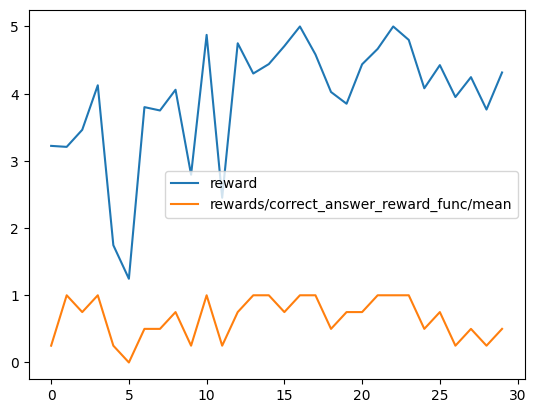

time: 1.98 s (started: 2026-06-07 19:38:27 +00:00)


In [19]:

import pandas as pd
import matplotlib.pyplot as plt

print(f"available columns: {trainer.state.log_history[0].keys()}")

log_df = pd.DataFrame(trainer.state.log_history)
log_df.to_csv('quick_train_grpo_logs.csv', index=True)
log_df["reward"].plot()
log_df["rewards/correct_answer_reward_func/mean"].plot()

plt.legend(["reward", "rewards/correct_answer_reward_func/mean"])
plt.show()

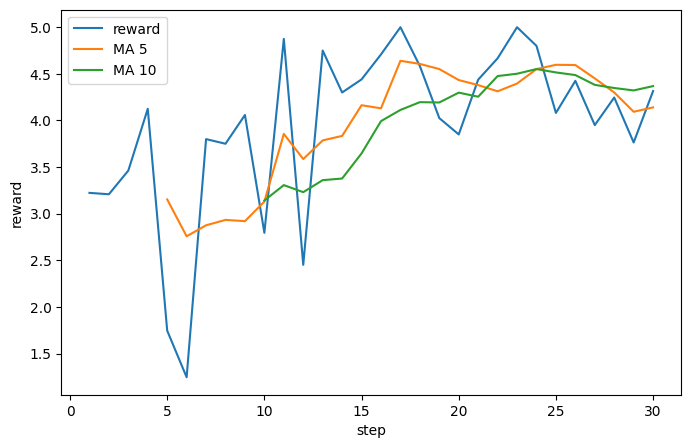

time: 135 ms (started: 2026-06-07 19:38:29 +00:00)


In [20]:
logs = pd.DataFrame(trainer.state.log_history)
logs.tail()

reward_logs = logs[logs["reward"].notna()].copy()
reward_logs["reward_ma5"] = reward_logs["reward"].rolling(5).mean()
reward_logs["reward_ma10"] = reward_logs["reward"].rolling(10).mean()

plt.figure(figsize=(8, 5))
plt.plot(reward_logs["step"], reward_logs["reward"], label="reward")
plt.plot(reward_logs["step"], reward_logs["reward_ma5"], label="MA 5")
plt.plot(reward_logs["step"], reward_logs["reward_ma10"], label="MA 10")
plt.legend()
plt.xlabel("step")
plt.ylabel("reward")
plt.show()

### Extended training run

The archived execution contains 200 steps. Runtime and reward trends are documented in PROJECT_EVIDENCE.md.

In [22]:

import unsloth
from unsloth import FastLanguageModel
import torch
import gc

try:
    del trainer
except NameError:
    pass
try:
    del model
except NameError:
    pass
try:
    del tokenizer
except NameError:
    pass

torch.cuda.empty_cache()
gc.collect()

max_seq_length = 384  
lora_rank = 16

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name="Qwen/Qwen2.5-3B-Instruct",
    max_seq_length=max_seq_length,
    load_in_4bit=True,
    fast_inference=True,
    max_lora_rank=lora_rank,
    gpu_memory_utilization=0.5,
)

model = FastLanguageModel.get_peft_model(
    model,
    r=lora_rank,
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj",
        "gate_proj",
        "up_proj",
        "down_proj",
    ],
    lora_alpha=lora_rank,
    use_gradient_checkpointing="unsloth",
)

INFO 06-07 19:43:27 [vllm_utils.py:688] Unsloth: Patching vLLM v1 graph capture
INFO 06-07 19:43:27 [vllm_utils.py:716] Unsloth: Patching vLLM v0 graph capture
==((====))==  Unsloth 2025.9.7: Fast Qwen2 patching. Transformers: 4.55.4. vLLM: 0.10.1.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.7.1+cu126. CUDA: 7.5. CUDA Toolkit: 12.6. Triton: 3.2.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.31. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: vLLM loading unsloth/qwen2.5-3b-instruct-unsloth-bnb-4bit with actual GPU utilization = 20.97%
Unsloth: Your GPU has CUDA compute capability 7.5 with VRAM = 14.56 GB.
Unsloth: Using conservativeness = 1.0. Chunked prefill tokens = 384. Num Sequences = 128.
Unsloth: vLLM's KV Cache can use up to 0.8 GB. Also swap space = 0 GB.
WARNING 06-07 19:43:29 [compilation.py:

Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00, 18.90it/s]

Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:01<00:00,  1.28s/it]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:01<00:00,  1.28s/it]



INFO 06-07 19:43:35 [model_runner.py:1112] Model loading took 2.2641 GiB and 2.143561 seconds
INFO 06-07 19:43:37 [worker.py:295] Memory profiling takes 1.43 seconds
INFO 06-07 19:43:37 [worker.py:295] the current vLLM instance can use total_gpu_memory (14.56GiB) x gpu_memory_utilization (0.21) = 3.05GiB
INFO 06-07 19:43:37 [worker.py:295] model weights take 2.26GiB; non_torch_memory takes 0.00GiB; PyTorch activation peak memory takes 0.70GiB; the rest of the memory reserved for KV Cache is 0.09GiB.
INFO 06-07 19:43:38 [executor_base.py:114] # cuda blocks: 170, # CPU blocks: 0
INFO 06-07 19:43:38 [executor_base.py:119] Maximum concurrency for 384 tokens per request: 7.08x
INFO 06-07 19:43:38 [vllm_utils.py:721] Unsloth: Running patched vLLM v0 `capture_model`.
INFO 06-07 19:43:38 [vllm_utils.py:721] Unsloth: Running patched vLLM v0 `capture_model`.
INFO 06-07 19:43:38 [vllm_utils.py:721] Unsloth: Running patched vLLM v0 `capture_model`.
INFO 06-07 19:43:38 [model_runner.py:1383] Captur

Capturing CUDA graph shapes: 100%|██████████| 19/19 [00:07<00:00,  2.42it/s]

INFO 06-07 19:43:46 [model_runner.py:1535] Graph capturing finished in 8 secs, took 0.08 GiB
INFO 06-07 19:43:46 [vllm_utils.py:728] Unsloth: Patched vLLM v0 graph capture finished in 8 secs.
INFO 06-07 19:43:46 [vllm_utils.py:728] Unsloth: Patched vLLM v0 graph capture finished in 8 secs.
INFO 06-07 19:43:46 [vllm_utils.py:728] Unsloth: Patched vLLM v0 graph capture finished in 8 secs.


INFO 06-07 19:43:47 [llm_engine.py:417] init engine (profile, create kv cache, warmup model) took 11.14 seconds
INFO 06-07 19:43:47 [llm.py:298] Supported_tasks: ['generate']
Unsloth: Just some info: will skip parsing ['post_attention_layernorm', 'k_norm', 'pre_feedforward_layernorm', 'layer_norm2', 'q_norm', 'post_layernorm', 'input_layernorm', 'norm1', 'norm2', 'layer_norm1', 'post_feedforward_layernorm']
Unsloth: Just some info: will skip parsing ['post_attention_layernorm', 'k_norm', 'pre_feedforward_layernorm', 'cross_attn_post_attention_layernorm', 'layer_norm2', 'q_norm', 'post_layernorm', 'input_layernorm', 'norm1', 'cross_attn_input_layernorm', 'norm2', 'layer_norm1', 'post_feedforward_layernorm']
time: 32.7 s (started: 2026-06-07 19:43:26 +00:00)


In [23]:

training_args = GRPOConfig(
    **COMMON_GRPO_TRAINING_PARAMS,
    max_steps=200,  # ~60min
)
trainer = GRPOTrainer(
    model=model,
    processing_class=tokenizer,
    reward_funcs=REWARD_FUNCS,
    args=training_args,
    train_dataset=ds,
)
trainer_res = trainer.train()

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 401 | Num Epochs = 1 | Total steps = 200
O^O/ \_/ \    Batch size per device = 4 | Gradient accumulation steps = 1
\        /    Data Parallel GPUs = 1 | Total batch size (4 x 1 x 1) = 4
 "-____-"     Trainable parameters = 29,933,568 of 3,115,872,256 (0.96% trained)



--------------------
Question: How many of the letter "g" are there in the word "glisten"
Answer: 1
Response: <reasoning>
Counting the number of g's in the word glisten
1. g - 1 so far
2. l - 0 so far
3. i - 0 so far
4. s - 0 so far
5. n - 0 so far
6. t - 0 so far
7. e - 0 so far
</reasoning>
<answer>
1
</answer>
Extracted: 1
Correct: True!
    


Step,Training Loss,reward,reward_std,completions / mean_length,completions / min_length,completions / max_length,completions / clipped_ratio,completions / mean_terminated_length,completions / min_terminated_length,completions / max_terminated_length,kl,rewards / numbering_reward_func / mean,rewards / numbering_reward_func / std,rewards / spelling_reward_func / mean,rewards / spelling_reward_func / std,rewards / counting_reward_func / mean,rewards / counting_reward_func / std,rewards / format_reward_func / mean,rewards / format_reward_func / std,rewards / correct_answer_reward_func / mean,rewards / correct_answer_reward_func / std
1,-0.000000,3.223145,0.677197,105.750000,93.000000,126.000000,0.000000,105.750000,93.000000,126.000000,0.000000,0.906250,0.062500,0.870605,0.109558,0.196411,0.931641,1.000000,0.000000,0.250000,0.500000
2,-0.000100,3.208313,0.583374,80.000000,67.000000,90.000000,0.000000,80.000000,67.000000,90.000000,0.000000,0.916504,0.166748,0.833496,0.333252,-0.541504,0.083252,1.000000,0.000000,1.000000,0.000000
3,0.000000,3.312561,0.723786,77.250000,38.000000,101.000000,0.000000,77.250000,38.000000,101.000000,0.000019,0.799805,0.399902,0.612305,0.774902,0.399902,0.516113,1.000000,0.000000,0.500000,0.577148
4,-0.000000,3.562378,1.007873,76.750000,39.000000,99.000000,0.000000,76.750000,39.000000,99.000000,0.000055,0.762695,0.354492,0.575195,0.722656,0.224976,0.895996,1.000000,0.000000,1.000000,0.000000
5,-0.000000,1.477722,0.126774,109.250000,102.000000,112.000000,0.000000,109.250000,102.000000,112.000000,0.002598,0.916504,0.055664,0.332031,0.087097,-0.770996,0.013916,1.000000,0.000000,0.000000,0.000000
6,-0.000100,3.824890,0.830342,67.250000,65.000000,74.000000,0.000000,67.250000,65.000000,74.000000,0.001739,0.950195,0.100098,0.950195,0.100098,0.175049,0.471436,1.000000,0.000000,0.750000,0.500000
7,0.000000,4.200012,0.565662,76.000000,76.000000,76.000000,0.000000,76.000000,76.000000,76.000000,0.002733,1.000000,0.000000,1.000000,0.000000,0.199951,0.565430,1.000000,0.000000,1.000000,0.000000
8,0.000100,3.908203,0.938710,64.250000,57.000000,77.000000,0.000000,64.250000,57.000000,77.000000,0.016861,0.825195,0.119019,0.700195,0.244873,0.633301,0.427002,1.000000,0.000000,0.750000,0.500000
9,0.000100,3.174072,0.644245,92.250000,85.000000,102.000000,0.000000,92.250000,85.000000,102.000000,0.009384,0.897461,0.069031,0.645996,0.161621,0.130981,0.595215,1.000000,0.000000,0.500000,0.577148
10,0.000000,3.285614,0.987169,87.250000,59.000000,115.000000,0.000000,87.250000,59.000000,115.000000,0.020294,0.755859,0.398682,0.589355,0.421143,0.440430,0.786133,1.000000,0.000000,0.500000,0.577148



--------------------
Question: How many of the letter "f" are there in the word "oath"
Answer: 0
Response: <reasoning>
Counting the number of f's in the word oath
1. o - 0 so far
2. a - 1 so far
3. t - 2 so far
4. h - 3 so far
5. - 4 so far
No letter "f" found
</reasoning>
<answer>
0
</answer>
Extracted: 0
Correct: True!
    

--------------------
Question: How many of the letter "a" are there in the word "knack"
Answer: 1
Response: <reasoning>
Counting the number of a's in the word knack
1. a - 1 so far
</reasoning>
<answer>
1
</answer>
Extracted: 1
Correct: True!
    

--------------------
Question: How many of the letter "w" are there in the word "wisp"
Answer: 1
Response: <reasoning>
Counting the number of w's in the word wisp
1. w - 1 so far
2. i - 0 so far (no additional w's found)
3. p - 0 so far (no additional w's found)
4. s - 0 so far (no additional w's found)
5. p - 0 so far (no additional w's found)
</reasoning>
<answer>
1
</answer>
Extracted: 1
Correct: True!
    

------

available columns: dict_keys(['loss', 'grad_norm', 'learning_rate', 'num_tokens', 'completions/mean_length', 'completions/min_length', 'completions/max_length', 'completions/clipped_ratio', 'completions/mean_terminated_length', 'completions/min_terminated_length', 'completions/max_terminated_length', 'rewards/numbering_reward_func/mean', 'rewards/numbering_reward_func/std', 'rewards/spelling_reward_func/mean', 'rewards/spelling_reward_func/std', 'rewards/counting_reward_func/mean', 'rewards/counting_reward_func/std', 'rewards/format_reward_func/mean', 'rewards/format_reward_func/std', 'rewards/correct_answer_reward_func/mean', 'rewards/correct_answer_reward_func/std', 'reward', 'reward_std', 'frac_reward_zero_std', 'completion_length', 'kl', 'epoch', 'step'])


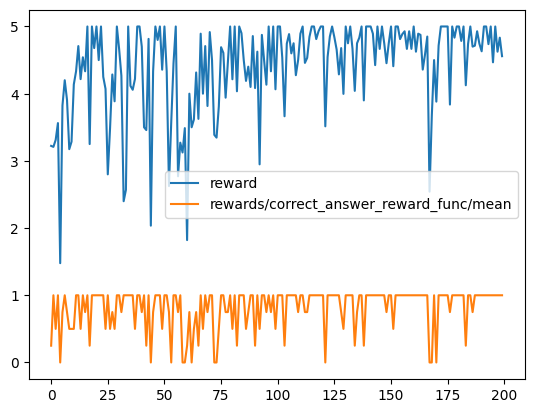

time: 199 ms (started: 2026-06-07 20:14:03 +00:00)


In [24]:

import pandas as pd
import matplotlib.pyplot as plt

print(f"available columns: {trainer.state.log_history[0].keys()}")

log_df = pd.DataFrame(trainer.state.log_history)
log_df.to_csv('slow_train_grpo_logs.csv')
log_df["reward"].plot()
log_df["rewards/correct_answer_reward_func/mean"].plot()

plt.legend(["reward", "rewards/correct_answer_reward_func/mean"])
plt.show()

## Adapter inspection

Load the trained adapter and inspect its generated responses.

In [25]:

model.save_lora("grpo_saved_lora")

time: 872 ms (started: 2026-06-07 20:14:25 +00:00)


In [ ]:

import gc
import torch
import unsloth
from vllm import SamplingParams
from unsloth import FastLanguageModel
from peft import PeftModel


try:
    del trainer
except NameError:
    pass
try:
    del model
except NameError:
    pass
try:
    del tokenizer
except NameError:
    pass

torch.cuda.empty_cache()
gc.collect()
max_seq_length = 384
lora_rank = 16
baseline_model, baseline_tokenizer = FastLanguageModel.from_pretrained(
    model_name="Qwen/Qwen2.5-3B-Instruct",
    max_seq_length=max_seq_length,
    load_in_4bit=True,  # We'll use quantization!
    fast_inference=True,  # This uses vllm for faster inference
    max_lora_rank=lora_rank,
    gpu_memory_utilization=0.5,  # You can reduce this if you get an memory error
)

new_model = PeftModel.from_pretrained(
    baseline_model,
    "grpo_saved_lora",
)

def compare_old_and_new_model(messages, baseline_model, baseline_tokenizer):


    text = baseline_tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )

    sampling_params = SamplingParams(
        temperature=0.8,
        top_p=0.95,
        max_tokens=1024,
    )

    old = (
        baseline_model.fast_generate(
            text,
            sampling_params=sampling_params,
        )[0]
        .outputs[0]
        .text
    )

    new = (
        new_model.fast_generate(
            text,
            sampling_params=sampling_params,
        )[0]
        .outputs[0]
        .text
    )

    print("===OLD===\n")
    print(old)

    print("\n\n===NEW===\n")
    print(new)


/voc/data/venv2/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
INFO 06-07 20:23:36 [__init__.py:241] Automatically detected platform cuda.
ERROR 06-07 20:23:38 [fa_utils.py:57] Cannot use FA version 2 is not supported due to FA2 is only supported on devices with compute capability >= 8
🦥 Unsloth Zoo will now patch everything to make training faster!
INFO 06-07 20:24:01 [vllm_utils.py:688] Unsloth: Patching vLLM v1 graph capture
INFO 06-07 20:24:01 [vllm_utils.py:716] Unsloth: Patching vLLM v0 graph capture
==((====))==  Unsloth 2025.9.7: Fast Qwen2 patching. Transformers: 4.55.4. vLLM: 0.10.1.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.7.1+cu126. CUDA: 7.5. CUDA Toolkit: 12.6. Triton: 3.2.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.31. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: vLLM 

2026-06-07 20:24:29,502	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


INFO 06-07 20:24:29 [scheduler.py:222] Chunked prefill is enabled with max_num_batched_tokens=2048.
Unsloth: vLLM Bitsandbytes config using kwargs = {'load_in_8bit': False, 'load_in_4bit': True, 'bnb_4bit_compute_dtype': 'float16', 'bnb_4bit_quant_storage': 'uint8', 'bnb_4bit_quant_type': 'nf4', 'bnb_4bit_use_double_quant': True, 'llm_int8_enable_fp32_cpu_offload': False, 'llm_int8_has_fp16_weight': False, 'llm_int8_skip_modules': ['lm_head', 'multi_modal_projector', 'merger', 'modality_projection', 'model.layers.2.mlp', 'model.layers.3.mlp', 'model.layers.30.mlp'], 'llm_int8_threshold': 6.0}
INFO 06-07 20:24:29 [llm_engine.py:222] Initializing a V0 LLM engine (v0.10.1) with config: model='unsloth/qwen2.5-3b-instruct-unsloth-bnb-4bit', speculative_config=None, tokenizer='unsloth/qwen2.5-3b-instruct-unsloth-bnb-4bit', skip_tokenizer_init=False, tokenizer_mode=auto, revision=None, override_neuron_config={}, tokenizer_revision=None, trust_remote_code=False, dtype=torch.float16, max_seq_le

[W607 20:24:31.560170838 socket.cpp:200] [c10d] The hostname of the client socket cannot be retrieved. err=-3
[W607 20:24:31.561152800 socket.cpp:200] [c10d] The hostname of the client socket cannot be retrieved. err=-3


...

INFO 06-07 20:24:34 [punica_selector.py:19] Using PunicaWrapperGPU.


INFO 06-07 20:24:35 [model_runner.py:1112] Model loading took 2.2719 GiB and 2.865005 seconds
INFO 06-07 20:24:39 [worker.py:295] Memory profiling takes 3.46 seconds
INFO 06-07 20:24:39 [worker.py:295] the current vLLM instance can use total_gpu_memory (14.56GiB) x gpu_memory_utilization (0.35) = 5.12GiB
INFO 06-07 20:24:39 [worker.py:295] model weights take 2.27GiB; non_torch_memory takes 0.03GiB; PyTorch activation peak memory takes 0.88GiB; the rest of the memory reserved for KV Cache is 1.94GiB.
INFO 06-07 20:24:39 [executor_base.py:114] # cuda blocks: 3535, # CPU blocks: 0
INFO 06-07 20:24:39 [executor_base.py:119] Maximum concurrency for 384 tokens per request: 147.29x
INFO 06-07 20:24:39 [vllm_utils.py:721] Unsloth: Running patched vLLM v0 `capture_model`.
INFO 06-07 20:24:39 [model_runner.py:1383] Capturing cudagraphs for decoding. This may lead to unexpected consequences if the model is not static. To run the model in eager mode, set 'enforce_eager=True' or use '--enforce-eage

Capturing CUDA graph shapes: 100%|██████████| 23/23 [00:10<00:00,  2.14it/s]

INFO 06-07 20:24:50 [model_runner.py:1535] Graph capturing finished in 11 secs, took 0.49 GiB
INFO 06-07 20:24:50 [vllm_utils.py:728] Unsloth: Patched vLLM v0 graph capture finished in 11 secs.


INFO 06-07 20:24:51 [llm_engine.py:417] init engine (profile, create kv cache, warmup model) took 15.68 seconds
INFO 06-07 20:24:51 [llm.py:298] Supported_tasks: ['generate']
Unsloth: Just some info: will skip parsing ['norm1', 'layer_norm1', 'post_layernorm', 'input_layernorm', 'q_norm', 'pre_feedforward_layernorm', 'layer_norm2', 'norm2', 'post_attention_layernorm', 'k_norm', 'post_feedforward_layernorm']
Unsloth: Just some info: will skip parsing ['norm1', 'cross_attn_post_attention_layernorm', 'cross_attn_input_layernorm', 'layer_norm1', 'post_layernorm', 'input_layernorm', 'q_norm', 'pre_feedforward_layernorm', 'layer_norm2', 'norm2', 'post_attention_layernorm', 'k_norm', 'post_feedforward_layernorm']
time: 1min 54s (started: 2026-06-07 20:23:02 +00:00)


### Base-model and adapter comparison

Compare both models on the same counting prompt.

In [19]:


SYSTEM_PROMPT = """"""
user_prompt = ds[0]['prompt'][1]['content']
messages = [
    {"role": "system", "content": SYSTEM_PROMPT},
    {
        "role": "user",
        "content": user_prompt,
    },
]
compare_old_and_new_model(messages, baseline_model, baseline_tokenizer)

Processed prompts: 100%|██████████| 1/1 [00:00<00:00,  2.18it/s, est. speed input: 63.41 toks/s, output: 32.80 toks/s]

===OLD===

There is one letter "a" in the word "idea".


===NEW===

There is 1 letter "a" in the word "idea".
time: 963 ms (started: 2026-06-07 20:34:34 +00:00)


### Comparison limits

Both saved responses answer the selected counting example correctly. A single example does not establish that the adapter outperforms the base model.

### Knowledge smoke test

Compare responses to one factual question. This is not a general test of knowledge retention or catastrophic forgetting.

In [20]:


SYSTEM_PROMPT = """"""
user_prompt = "What is the capital of France?"
messages = [
    {"role": "system", "content": SYSTEM_PROMPT},
    {
        "role": "user",
        "content": user_prompt,
    },
]
compare_old_and_new_model(messages, baseline_model, baseline_tokenizer)

Processed prompts: 100%|██████████| 1/1 [00:00<00:00,  3.40it/s, est. speed input: 68.42 toks/s, output: 27.36 toks/s]

===OLD===

The capital of France is Paris.


===NEW===

The capital of France is Paris.
time: 673 ms (started: 2026-06-07 20:35:05 +00:00)


## Experiment summary

The record demonstrates adapter training with five programmatic rewards and saved outputs. See PROJECT_EVIDENCE.md for measured training signals and evaluation limits. The original course notebook remains available in Git history.